In [1]:
# CELL 0: NOTEBOOK PATH SETUP
# What this cell does:
#   - Adds the project root to Python's import path so this notebook can import
#     from src/, and turns on autoreload for edits to files in src/.

import sys
from pathlib import Path

project_root = Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

%load_ext autoreload
%autoreload 2

print("Project root:", project_root)

Project root: c:\Users\blbon\Desktop\MyWorkspace\FYP\personal projects\rf-anomaly


In [2]:
# CELL 1: LOAD THE SAVED SPLITS AND COMPUTE FEATURES
# What this cell does:
#   - Loads data/train.npz, val.npz and test.npz made by scripts/build_dataset.py.
#   - Removes the ambiguous windows (label -1), which count as neither normal nor
#     anomalous.
#   - Computes the 13 features for every kept window and then drops the raw I/Q
#     arrays to save memory. Features take only a few seconds.
#   - Prints, per split: windows kept, feature matrix shape and the number of
#     normal and anomalous windows.
#   - Expected: train 4500 normal / 0 anomalous; val 1570 / 481; test 3195 / 1455
#     (about +-30 if your machine draws slightly different random numbers).

import time
import numpy as np
import matplotlib.pyplot as plt

from src.dsp.features import FEATURE_NAMES, window_features
from src.eval.metrics import (family_report, false_alarm_rate, rate_by_bin,
                              threshold_at_far)

data_dir = project_root / "data"
splits = {}
t0 = time.time()
for name in ["train", "val", "test"]:
    d = np.load(data_dir / f"{name}.npz")
    s = {k: d[k] for k in d.files}
    keep = s["y"] != -1
    s["feat"] = window_features(s["x"][keep])
    for k in ["y", "family", "snr_db", "rec_id"]:
        s[k] = s[k][keep]
    del s["x"]
    splits[name] = s
    print(f"{name:5s}: windows kept {keep.sum():5d} | features {s['feat'].shape} | "
          f"normal {np.sum(s['y'] == 0)} anomalous {np.sum(s['y'] == 1)}")
print(f"Feature time: {time.time() - t0:.1f} s")
print(FEATURE_NAMES)

train: windows kept  4500 | features (4500, 13) | normal 4500 anomalous 0
val  : windows kept  2051 | features (2051, 13) | normal 1570 anomalous 481
test : windows kept  4650 | features (4650, 13) | normal 3195 anomalous 1455
Feature time: 15.7 s
['power_db', 'flatness', 'centroid', 'spread', 'peak_to_median_db', 'dynamic_range_db', 'centroid_shift', 'spectral_flux', 'temporal_var', 'env_kurtosis', 'papr_db', 'line2_db', 'line4_db']


In [3]:
# CELL 2: TWO CLASSICAL SCALAR BASELINES
# What this cell does:
#   - Baseline A "Energy detector": score = window power in dB.
#   - Baseline B "Peak-to-median": score = strongest PSD bin vs the median bin (dB),
#     a simple narrowband-interference detector.
#   - For each baseline: sets the threshold on VALIDATION normal windows so that
#     1% (and separately 5%) of them are flagged, then applies it to the TEST set.
#   - Prints the thresholds, the false-alarm rate actually obtained on test
#     normals, and for each anomaly family: number of anomalous windows, AUROC,
#     AUPRC and detection rate at 1% and 5% false alarms.
#   - Expected approx: Energy detector AUROC 0.5-0.72 and detection under 10%;
#     Peak-to-median AUROC about 0.33-0.55 and detection under 10%. Both are
#     close to useless. Test FAR can differ from the target (e.g. 0.5% or 2%
#     instead of 1%) because the 1% threshold rests on only ~16 validation windows.
#   - Needs Cell 1.

baselines = {"Energy detector": "power_db", "Peak-to-median": "peak_to_median_db"}
val, test = splits["val"], splits["test"]
thr = {}

for label, feat in baselines.items():
    j = FEATURE_NAMES.index(feat)
    for far in (0.01, 0.05):
        thr[(label, far)] = threshold_at_far(val["feat"][val["y"] == 0, j], far)
    sc = test["feat"][:, j]
    print(f"\n{label}: thr@1% = {thr[(label, 0.01)]:.2f}, thr@5% = {thr[(label, 0.05)]:.2f}")
    print(f"  actual test FAR @1%: {false_alarm_rate(sc[test['y'] == 0], thr[(label, 0.01)]):.3f}"
          f"  @5%: {false_alarm_rate(sc[test['y'] == 0], thr[(label, 0.05)]):.3f}")
    rep1 = family_report(sc, test["y"], test["family"], thr[(label, 0.01)])
    rep5 = family_report(sc, test["y"], test["family"], thr[(label, 0.05)])
    print(f"  {'family':12s} | {'n':>4s} | {'AUROC':>6s} | {'AUPRC':>6s} | {'det@1%':>6s} | {'det@5%':>6s}")
    for fam, r in rep1.items():
        print(f"  {fam:12s} | {r['n']:4d} | {r['auroc']:6.3f} | {r['auprc']:6.3f} | "
              f"{r['det_rate']:6.3f} | {rep5[fam]['det_rate']:6.3f}")


Energy detector: thr@1% = 5.99, thr@5% = 5.10
  actual test FAR @1%: 0.005  @5%: 0.056
  family       |    n |  AUROC |  AUPRC | det@1% | det@5%
  chirp        |  241 |  0.688 |  0.099 |  0.000 |  0.000
  drift        |  242 |  0.475 |  0.069 |  0.000 |  0.066
  hopping      |  239 |  0.696 |  0.128 |  0.029 |  0.100
  mod_swap     |  246 |  0.504 |  0.085 |  0.024 |  0.057
  noise_burst  |  248 |  0.679 |  0.106 |  0.012 |  0.044
  tone         |  239 |  0.720 |  0.131 |  0.033 |  0.054

Peak-to-median: thr@1% = 37.29, thr@5% = 36.12
  actual test FAR @1%: 0.020  @5%: 0.037
  family       |    n |  AUROC |  AUPRC | det@1% | det@5%
  chirp        |  241 |  0.512 |  0.070 |  0.000 |  0.004
  drift        |  242 |  0.514 |  0.077 |  0.012 |  0.041
  hopping      |  239 |  0.493 |  0.068 |  0.000 |  0.033
  mod_swap     |  246 |  0.459 |  0.066 |  0.024 |  0.045
  noise_burst  |  248 |  0.335 |  0.050 |  0.000 |  0.000
  tone         |  239 |  0.554 |  0.146 |  0.092 |  0.100


In [4]:
# CELL 3: FALSE ALARMS AND DETECTIONS BY SNR
# What this cell does:
#   - Takes the 5%-false-alarm thresholds from Cell 2 and splits the TEST
#     windows into SNR bins (-5..0, 0..5, ... 20..25 dB).
#   - For each baseline and bin, prints the fraction of NORMAL windows flagged
#     (FAR) and of ANOMALOUS windows flagged (detection), with window counts.
#   - Expected: the two baselines behave very differently across SNR. The Energy
#     detector flags windows only in the lowest-SNR bin; Peak-to-median flags
#     windows almost only in the highest-SNR bin. In the other bins both flag
#     almost nothing, normal or anomalous alike.
#   - Needs Cells 1 and 2.

edges = np.array([-5, 0, 5, 10, 15, 20, 25.1])
for label, feat in baselines.items():
    j = FEATURE_NAMES.index(feat)
    sc = test["feat"][:, j]
    t = thr[(label, 0.05)]
    normal, anom = test["y"] == 0, test["y"] == 1
    far_bins = rate_by_bin(sc[normal], test["snr_db"][normal], t, edges)
    det_bins = rate_by_bin(sc[anom], test["snr_db"][anom], t, edges)
    print(label)
    for (lo, hi, fr, nf), (_, _, dr, nd) in zip(far_bins, det_bins):
        print(f"  SNR {lo:5.0f}..{hi:3.0f} | FAR {fr:5.3f} (n={nf:4d}) | det {dr:5.3f} (n={nd:4d})")

Energy detector
  SNR    -5..  0 | FAR 0.365 (n= 490) | det 0.326 (n= 239)
  SNR     0..  5 | FAR 0.000 (n= 644) | det 0.000 (n= 306)
  SNR     5.. 10 | FAR 0.000 (n= 518) | det 0.000 (n= 197)
  SNR    10.. 15 | FAR 0.000 (n= 484) | det 0.000 (n= 243)
  SNR    15.. 20 | FAR 0.000 (n= 556) | det 0.000 (n= 242)
  SNR    20.. 25 | FAR 0.000 (n= 503) | det 0.000 (n= 228)
Peak-to-median
  SNR    -5..  0 | FAR 0.000 (n= 490) | det 0.000 (n= 239)
  SNR     0..  5 | FAR 0.000 (n= 644) | det 0.000 (n= 306)
  SNR     5.. 10 | FAR 0.000 (n= 518) | det 0.000 (n= 197)
  SNR    10.. 15 | FAR 0.000 (n= 484) | det 0.000 (n= 243)
  SNR    15.. 20 | FAR 0.011 (n= 556) | det 0.000 (n= 242)
  SNR    20.. 25 | FAR 0.223 (n= 503) | det 0.237 (n= 228)


In [9]:
# CELL 4: ISOLATION FOREST AND ONE-CLASS SVM, SAME HARNESS
# What this cell does:
#   - Loads the cached features for train / val / test (ambiguous windows removed).
#   - Trains each detector on the 4,500 normal TRAIN windows only.
#   - Sets thresholds on VALIDATION normal windows (1% and 5% false alarms),
#     then applies them to the TEST set.
#   - Prints, per detector: test FAR at both thresholds; per family the AUROC,
#     AUPRC and detection rate at 1% and 5%; then FAR and detection by SNR bin
#     (5% threshold).
#   - Expected: clearly better than the two baselines on several families, FAR
#     more even across SNR bins, and mod_swap still weak.

import numpy as np
from src.data.loading import load_features
from src.models.classical import isolation_forest, one_class_svm
from src.eval.metrics import family_report, false_alarm_rate, rate_by_bin, threshold_at_far

dd = project_root / "data"
train, val, test = (load_features(s, dd) for s in ["train", "val", "test"])
edges = np.array([-5, 0, 5, 10, 15, 20, 25.1])
normal, anom = test["y"] == 0, test["y"] == 1

detectors = {"Isolation Forest": isolation_forest(),
             "One-Class SVM": one_class_svm(nu=0.05)}

for label, det in detectors.items():
    det.fit(train["feat"])
    s_val, s_test = det.score(val["feat"]), det.score(test["feat"])
    t1 = threshold_at_far(s_val[val["y"] == 0], 0.01)
    t5 = threshold_at_far(s_val[val["y"] == 0], 0.05)
    print(f"\n{label}: test FAR @1% {false_alarm_rate(s_test[normal], t1):.3f}"
          f"  @5% {false_alarm_rate(s_test[normal], t5):.3f}")
    r1 = family_report(s_test, test["y"], test["family"], t1)
    r5 = family_report(s_test, test["y"], test["family"], t5)
    print(f"  {'family':12s} | {'n':>4s} | {'AUROC':>6s} | {'AUPRC':>6s} | {'det@1%':>6s} | {'det@5%':>6s}")
    for fam, r in r1.items():
        print(f"  {fam:12s} | {r['n']:4d} | {r['auroc']:6.3f} | {r['auprc']:6.3f} | "
              f"{r['det_rate']:6.3f} | {r5[fam]['det_rate']:6.3f}")
    fb = rate_by_bin(s_test[normal], test["snr_db"][normal], t5, edges)
    db = rate_by_bin(s_test[anom], test["snr_db"][anom], t5, edges)
    for (lo, hi, fr, nf), (_, _, dr, nd) in zip(fb, db):
        print(f"  SNR {lo:5.0f}..{hi:3.0f} | FAR {fr:5.3f} (n={nf:4d}) | det {dr:5.3f} (n={nd:4d})")


Isolation Forest: test FAR @1% 0.010  @5% 0.045
  family       |    n |  AUROC |  AUPRC | det@1% | det@5%
  chirp        |  241 |  0.959 |  0.715 |  0.502 |  0.751
  drift        |  242 |  0.921 |  0.615 |  0.351 |  0.665
  hopping      |  239 |  0.907 |  0.608 |  0.377 |  0.640
  mod_swap     |  246 |  0.482 |  0.077 |  0.016 |  0.085
  noise_burst  |  248 |  0.696 |  0.221 |  0.105 |  0.198
  tone         |  239 |  0.763 |  0.304 |  0.172 |  0.314
  SNR    -5..  0 | FAR 0.178 (n= 490) | det 0.293 (n= 239)
  SNR     0..  5 | FAR 0.022 (n= 644) | det 0.408 (n= 306)
  SNR     5.. 10 | FAR 0.008 (n= 518) | det 0.325 (n= 197)
  SNR    10.. 15 | FAR 0.002 (n= 484) | det 0.449 (n= 243)
  SNR    15.. 20 | FAR 0.009 (n= 556) | det 0.446 (n= 242)
  SNR    20.. 25 | FAR 0.068 (n= 503) | det 0.719 (n= 228)

One-Class SVM: test FAR @1% 0.004  @5% 0.034
  family       |    n |  AUROC |  AUPRC | det@1% | det@5%
  chirp        |  241 |  0.982 |  0.956 |  0.909 |  0.942
  drift        |  242 |  0.95

In [10]:
# CELL 5 (FIXED): FEATURE SUBSET ABLATION + SMALL OCSVM SEARCH
# What this cell does:
#   - Same as before, but the anomalies of a family are now selected with
#     (y == 1) & (family == f), exactly like family_report, so recording-level
#     labels on normal windows no longer pollute the result.
#   - Part A: IF and OCSVM on feature subsets, AUROC per family on TEST.
#   - Part B: OCSVM nu x gamma search, selected ONLY on the two validation
#     families (anomalies in val), then reported on TEST.
#   - Needs Cell 4 (train, val, test, isolation_forest, one_class_svm, FEATURE_NAMES).

import numpy as np
from src.dsp.features import FEATURE_NAMES
from src.eval.metrics import auroc

def fam_auc(s, d, f):
    n = d["y"] == 0
    a = (d["y"] == 1) & (d["family"] == f)
    return auroc(s[n], s[a])

tfams = sorted(str(f) for f in set(test["family"][test["y"] == 1]))
vfams = sorted(str(f) for f in set(val["family"][val["y"] == 1]))

subsets = {
    "all13": None,
    "no_snr_like": [n for n in FEATURE_NAMES
                    if n not in ("power_db", "peak_to_median_db", "dynamic_range_db")],
    "line_only": ["line2_db", "line4_db"],
    "spectral_shape": ["flatness", "centroid", "spread"],
}
print("PART A: TEST AUROC per family")
print(f"{'model/subset':28s} " + " ".join(f"{f[:8]:>8s}" for f in tfams))
makers = {"IF": lambda cols: isolation_forest(feature_names=cols),
          "OCSVM": lambda cols: one_class_svm(0.05, feature_names=cols)}
for mname, make in makers.items():
    for sname, cols in subsets.items():
        s = make(cols).fit(train["feat"]).score(test["feat"])
        print(f"{mname + ' / ' + sname:28s} " + " ".join(f"{fam_auc(s, test, f):8.3f}" for f in tfams))

print("\nPART B: OCSVM search, selected on VALIDATION anomalies")
print("val families:", vfams)
results = []
for nu in (0.01, 0.05, 0.1):
    for g in (0.01, 0.03, 0.1, "scale"):
        det = one_class_svm(nu=nu, gamma=g).fit(train["feat"])
        sv, st = det.score(val["feat"]), det.score(test["feat"])
        v_auc = float(np.mean([fam_auc(sv, val, f) for f in vfams]))
        results.append((v_auc, nu, g, {f: fam_auc(st, test, f) for f in tfams}))
        print(f"nu={nu:<5} gamma={str(g):6s} | val mean AUROC {v_auc:.3f}")
best = max(results, key=lambda r: r[0])
print(f"\nBest on validation: nu={best[1]}, gamma={best[2]} (val AUROC {best[0]:.3f})")
print("Its TEST AUROC per family:", {f: round(a, 3) for f, a in best[3].items()})

PART A: TEST AUROC per family
model/subset                    chirp    drift  hopping mod_swap noise_bu     tone
IF / all13                      0.959    0.921    0.907    0.482    0.696    0.763
IF / no_snr_like                0.963    0.934    0.895    0.482    0.692    0.702
IF / line_only                  0.479    0.674    0.567    0.521    0.543    0.652
IF / spectral_shape             0.537    0.491    0.657    0.469    0.627    0.594
OCSVM / all13                   0.982    0.951    0.901    0.483    0.630    0.615
OCSVM / no_snr_like             0.985    0.960    0.911    0.509    0.625    0.621
OCSVM / line_only               0.523    0.674    0.417    0.523    0.533    0.395
OCSVM / spectral_shape          0.547    0.534    0.672    0.479    0.540    0.611

PART B: OCSVM search, selected on VALIDATION anomalies
val families: ['noise_burst', 'tone']
nu=0.01  gamma=0.01   | val mean AUROC 0.506
nu=0.01  gamma=0.03   | val mean AUROC 0.552
nu=0.01  gamma=0.1    | val mean AUROC 

In [7]:
# CELL 6: DIAGNOSTIC, WHY DO CELL 4 AND CELL 5 DISAGREE?
# What this cell does:
#   - Prints a fingerprint of the data currently in memory (shape, feature sum,
#     label counts) and the modification times of the data files.
#   - Re-runs exactly the Cell 4 Isolation Forest and prints AUROC per family
#     with BOTH the family_report function and the direct calculation Cell 5 used.
#   - Needs Cell 4 (it reuses train, val, test).

import os, time
import numpy as np
from src.eval.metrics import auroc, family_report, threshold_at_far

for n, s in [("train", train), ("val", val), ("test", test)]:
    print(n, s["feat"].shape, "feat sum", round(float(s["feat"].sum()), 3),
          dict(zip(*np.unique(s["y"], return_counts=True))))
for f in ["train", "val", "test", "train_features", "val_features", "test_features"]:
    p = dd / f"{f}.npz"
    print(f"{f:15s}", time.ctime(os.path.getmtime(p)))

normal = test["y"] == 0
anom = test["y"] == 1
print("normal", normal.sum(), "anom", anom.sum(), "total", len(test["y"]))

det = isolation_forest().fit(train["feat"])
s = det.score(test["feat"])
thr = threshold_at_far(det.score(val["feat"])[val["y"] == 0], 0.05)
rep = family_report(s, test["y"], test["family"], thr)
for f in sorted(set(test["family"][anom])):
    direct = auroc(s[normal], s[test["family"] == f])
    print(f"{f:12s} family_report {rep[f]['auroc']:.3f} | direct {direct:.3f}")

train (4500, 13) feat sum 373214.07 {np.int64(0): np.int64(4500)}
val (2051, 13) feat sum 167820.039 {np.int64(0): np.int64(1570), np.int64(1): np.int64(481)}
test (4650, 13) feat sum 374004.85 {np.int64(0): np.int64(3195), np.int64(1): np.int64(1455)}
train           Sun Oct 25 11:27:11 2026
val             Sun Oct 25 11:27:12 2026
test            Sun Oct 25 11:27:14 2026
train_features  Sun Oct 25 11:39:05 2026
val_features    Sun Oct 25 11:39:07 2026
test_features   Sun Oct 25 11:39:13 2026
normal 3195 anom 1455 total 4650
chirp        family_report 0.959 | direct 0.644
drift        family_report 0.921 | direct 0.694
hopping      family_report 0.907 | direct 0.664
mod_swap     family_report 0.482 | direct 0.461
noise_burst  family_report 0.696 | direct 0.594
tone         family_report 0.763 | direct 0.586


In [2]:
# CELL 7: AUTOENCODER ON THE SPECTROGRAM, SAME HARNESS
# What this cell does:
#   - Loads the raw I/Q windows (ambiguous removed, same order as load_features),
#     converts each to a 1024-number spectrogram, then drops the raw I/Q.
#   - Trains the autoencoder on the 4,500 normal TRAIN windows only.
#   - Sets thresholds on VALIDATION normals (1% and 5%), applies them to TEST.
#   - Prints test FAR, per-family AUROC/AUPRC/detection, and FAR/detection by SNR.
#   - Takes about 1 to 3 minutes.

import time
import numpy as np
from src.dsp.spectro import window_spectrogram
from src.models.autoencoder import AutoencoderDetector
from src.eval.metrics import family_report, false_alarm_rate, rate_by_bin, threshold_at_far

def load_spectro(split):
    with np.load(project_root / "data" / f"{split}.npz") as z:
        keep = z["y"] != -1
        return {"spec": window_spectrogram(z["x"][keep]), "y": z["y"][keep],
                "family": z["family"][keep], "snr_db": z["snr_db"][keep]}

t0 = time.time()
tr, va, te = (load_spectro(s) for s in ["train", "val", "test"])
print(f"spectrograms ready in {time.time() - t0:.1f}s", tr["spec"].shape, va["spec"].shape, te["spec"].shape)

det = AutoencoderDetector().fit(tr["spec"])
print(f"trained in {time.time() - t0:.1f}s total, iterations: {det.model.n_iter_}")
s_val, s_te = det.score(va["spec"]), det.score(te["spec"])
t1 = threshold_at_far(s_val[va["y"] == 0], 0.01)
t5 = threshold_at_far(s_val[va["y"] == 0], 0.05)
nrm, anm = te["y"] == 0, te["y"] == 1
edges = np.array([-5, 0, 5, 10, 15, 20, 25.1])

print(f"\nAutoencoder: test FAR @1% {false_alarm_rate(s_te[nrm], t1):.3f}  @5% {false_alarm_rate(s_te[nrm], t5):.3f}")
r1 = family_report(s_te, te["y"], te["family"], t1)
r5 = family_report(s_te, te["y"], te["family"], t5)
print(f"  {'family':12s} | {'n':>4s} | {'AUROC':>6s} | {'AUPRC':>6s} | {'det@1%':>6s} | {'det@5%':>6s}")
for fam, r in r1.items():
    print(f"  {fam:12s} | {r['n']:4d} | {r['auroc']:6.3f} | {r['auprc']:6.3f} | "
          f"{r['det_rate']:6.3f} | {r5[fam]['det_rate']:6.3f}")
fb = rate_by_bin(s_te[nrm], te["snr_db"][nrm], t5, edges)
db = rate_by_bin(s_te[anm], te["snr_db"][anm], t5, edges)
for (lo, hi, fr, nf), (_, _, dr, nd) in zip(fb, db):
    print(f"  SNR {lo:5.0f}..{hi:3.0f} | FAR {fr:5.3f} (n={nf:4d}) | det {dr:5.3f} (n={nd:4d})")

spectrograms ready in 2.7s (4500, 1024) (2051, 1024) (4650, 1024)
trained in 42.7s total, iterations: 51

Autoencoder: test FAR @1% 0.004  @5% 0.035
  family       |    n |  AUROC |  AUPRC | det@1% | det@5%
  chirp        |  241 |  0.880 |  0.682 |  0.465 |  0.639
  drift        |  242 |  0.632 |  0.213 |  0.074 |  0.207
  hopping      |  239 |  0.951 |  0.823 |  0.661 |  0.774
  mod_swap     |  246 |  0.514 |  0.073 |  0.004 |  0.028
  noise_burst  |  248 |  0.613 |  0.272 |  0.173 |  0.202
  tone         |  239 |  0.815 |  0.619 |  0.506 |  0.573
  SNR    -5..  0 | FAR 0.002 (n= 490) | det 0.142 (n= 239)
  SNR     0..  5 | FAR 0.012 (n= 644) | det 0.353 (n= 306)
  SNR     5.. 10 | FAR 0.004 (n= 518) | det 0.462 (n= 197)
  SNR    10.. 15 | FAR 0.027 (n= 484) | det 0.481 (n= 243)
  SNR    15.. 20 | FAR 0.047 (n= 556) | det 0.401 (n= 242)
  SNR    20.. 25 | FAR 0.125 (n= 503) | det 0.596 (n= 228)


In [12]:
# CELL 8: COMBINE IF + OCSVM + AUTOENCODER
# What this cell does:
#   - Trains Isolation Forest (13 features) and One-Class SVM (no SNR-like
#     features) on normal TRAIN windows; reuses the autoencoder from Cell 7.
#   - Rescales the three scores using VALIDATION normals, merges them with
#     "max" and with "mean", sets thresholds on validation normals (1%, 5%),
#     and applies them to TEST.
#   - Prints per mode: test FAR, per-family AUROC/AUPRC/detection, and FAR and
#     detection by SNR bin. Finishes with one AUROC table of all detectors.
#   - Takes about 30 seconds.

import numpy as np
from src.data.loading import load_features
from src.dsp.features import FEATURE_NAMES
from src.models.classical import isolation_forest, one_class_svm
from src.models.fusion import ScoreFusion
from src.eval.metrics import family_report, false_alarm_rate, rate_by_bin, threshold_at_far

dd = project_root / "data"
F = {s: load_features(s, dd) for s in ["train", "val", "test"]}
assert np.array_equal(F["val"]["y"], va["y"]) and np.array_equal(F["test"]["y"], te["y"]), "row order mismatch"

no_snr = [n for n in FEATURE_NAMES if n not in ("power_db", "peak_to_median_db", "dynamic_range_db")]
d_if = isolation_forest().fit(F["train"]["feat"])
d_sv = one_class_svm(nu=0.05, feature_names=no_snr).fit(F["train"]["feat"])

def three_scores(split, spec):
    return [d_if.score(F[split]["feat"]), d_sv.score(F[split]["feat"]), det.score(spec)]

sc_val, sc_te = three_scores("val", va["spec"]), three_scores("test", te["spec"])
vn = va["y"] == 0
nrm, anm = te["y"] == 0, te["y"] == 1
edges = np.array([-5, 0, 5, 10, 15, 20, 25.1])
table = {}

for mode in ("max", "mean"):
    fus = ScoreFusion(mode).fit([s[vn] for s in sc_val])
    s_val, s_te = fus.combine(sc_val), fus.combine(sc_te)
    t1 = threshold_at_far(s_val[vn], 0.01)
    t5 = threshold_at_far(s_val[vn], 0.05)
    print(f"\nFUSION ({mode}): test FAR @1% {false_alarm_rate(s_te[nrm], t1):.3f}"
          f"  @5% {false_alarm_rate(s_te[nrm], t5):.3f}")
    r1 = family_report(s_te, te["y"], te["family"], t1)
    r5 = family_report(s_te, te["y"], te["family"], t5)
    print(f"  {'family':12s} | {'n':>4s} | {'AUROC':>6s} | {'AUPRC':>6s} | {'det@1%':>6s} | {'det@5%':>6s}")
    for fam, r in r1.items():
        print(f"  {fam:12s} | {r['n']:4d} | {r['auroc']:6.3f} | {r['auprc']:6.3f} | "
              f"{r['det_rate']:6.3f} | {r5[fam]['det_rate']:6.3f}")
    fb = rate_by_bin(s_te[nrm], te["snr_db"][nrm], t5, edges)
    db = rate_by_bin(s_te[anm], te["snr_db"][anm], t5, edges)
    for (lo, hi, fr, nf), (_, _, dr, nd) in zip(fb, db):
        print(f"  SNR {lo:5.0f}..{hi:3.0f} | FAR {fr:5.3f} (n={nf:4d}) | det {dr:5.3f} (n={nd:4d})")
    table[f"fusion {mode}"] = {f: r["auroc"] for f, r in r1.items()}

for name, s in [("IF", sc_te[0]), ("OCSVM no_snr", sc_te[1]), ("Autoencoder", sc_te[2])]:
    t = threshold_at_far(sc_val[["IF", "OCSVM no_snr", "Autoencoder"].index(name)][vn], 0.05)
    table[name] = {f: r["auroc"] for f, r in family_report(s, te["y"], te["family"], t).items()}

fams = list(table["IF"])
print("\nTEST AUROC, ALL DETECTORS")
print(f"{'detector':14s} " + " ".join(f"{f[:8]:>8s}" for f in fams))
for name, row in table.items():
    print(f"{name:14s} " + " ".join(f"{row[f]:8.3f}" for f in fams))


FUSION (max): test FAR @1% 0.003  @5% 0.037
  family       |    n |  AUROC |  AUPRC | det@1% | det@5%
  chirp        |  241 |  0.983 |  0.944 |  0.867 |  0.934
  drift        |  242 |  0.939 |  0.815 |  0.595 |  0.802
  hopping      |  239 |  0.950 |  0.847 |  0.720 |  0.816
  mod_swap     |  246 |  0.513 |  0.095 |  0.020 |  0.053
  noise_burst  |  248 |  0.652 |  0.311 |  0.198 |  0.258
  tone         |  239 |  0.888 |  0.705 |  0.510 |  0.682
  SNR    -5..  0 | FAR 0.065 (n= 490) | det 0.343 (n= 239)
  SNR     0..  5 | FAR 0.012 (n= 644) | det 0.585 (n= 306)
  SNR     5.. 10 | FAR 0.002 (n= 518) | det 0.553 (n= 197)
  SNR    10.. 15 | FAR 0.012 (n= 484) | det 0.671 (n= 243)
  SNR    15.. 20 | FAR 0.034 (n= 556) | det 0.562 (n= 242)
  SNR    20.. 25 | FAR 0.101 (n= 503) | det 0.811 (n= 228)

FUSION (mean): test FAR @1% 0.005  @5% 0.033
  family       |    n |  AUROC |  AUPRC | det@1% | det@5%
  chirp        |  241 |  0.983 |  0.941 |  0.867 |  0.938
  drift        |  242 |  0.942 | 

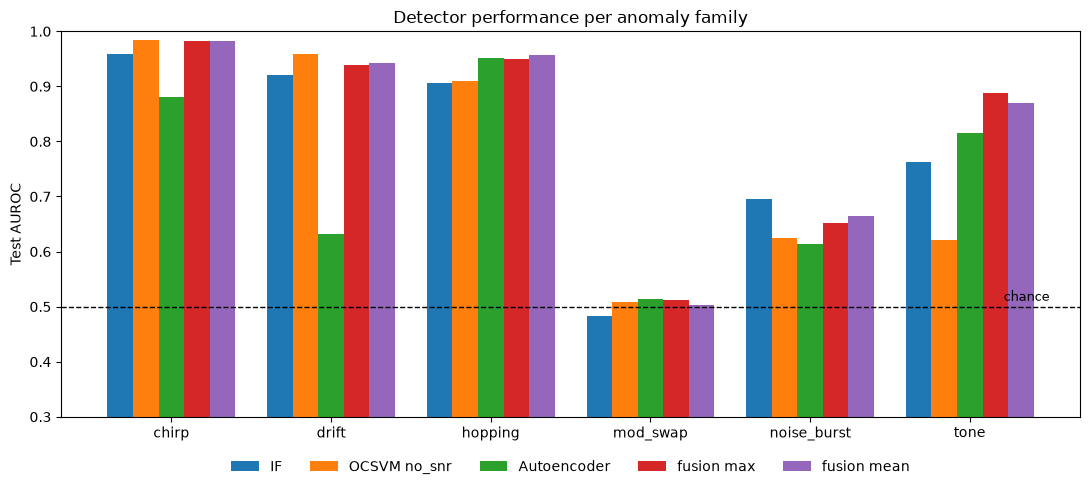

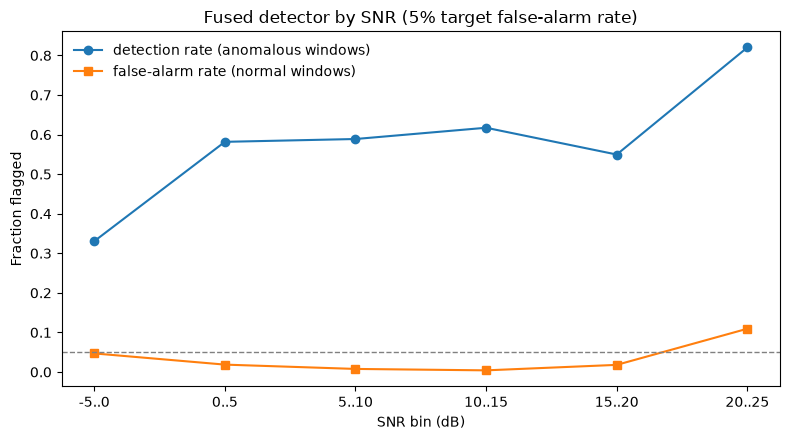

Saved to c:\Users\blbon\Desktop\MyWorkspace\FYP\personal projects\rf-anomaly\figures


In [13]:
# CELL 9: FINAL FIGURES AND RESULTS FILE
# What this cell does:
#   - Figure 1: test AUROC per anomaly family for every detector (bar chart),
#     saved to figures/auroc_by_family.png.
#   - Figure 2: false-alarm rate and detection rate by SNR bin for the fused
#     detector ("mean", the last mode run in Cell 8), saved to
#     figures/fusion_by_snr.png.
#   - Saves the AUROC table to figures/auroc_table.csv.
#   - Needs Cell 8.

import csv
import numpy as np
import matplotlib.pyplot as plt

fig_dir = project_root / "figures"
fig_dir.mkdir(exist_ok=True)

order = ["IF", "OCSVM no_snr", "Autoencoder", "fusion max", "fusion mean"]
fams = list(table["IF"])

# Figure 1: AUROC per family
fig, ax = plt.subplots(figsize=(11, 5))
w = 0.16
x = np.arange(len(fams))
for i, name in enumerate(order):
    ax.bar(x + (i - 2) * w, [table[name][f] for f in fams], w, label=name)
ax.axhline(0.5, color="black", linestyle="--", linewidth=1)
ax.text(len(fams) - 0.5, 0.505, "chance", ha="right", va="bottom", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(fams)
ax.set_ylim(0.3, 1.0)
ax.set_ylabel("Test AUROC")
ax.set_title("Detector performance per anomaly family")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.08), frameon=False)
fig.tight_layout()
fig.savefig(fig_dir / "auroc_by_family.png", dpi=200)
plt.show()

# Figure 2: FAR and detection by SNR (fusion mean, 5% threshold)
fb = rate_by_bin(s_te[nrm], te["snr_db"][nrm], t5, edges)
db = rate_by_bin(s_te[anm], te["snr_db"][anm], t5, edges)
labels = [f"{lo:.0f}..{min(hi, 25):.0f}" for lo, hi, _, _ in fb]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(labels, [r[2] for r in db], marker="o", label="detection rate (anomalous windows)")
ax.plot(labels, [r[2] for r in fb], marker="s", label="false-alarm rate (normal windows)")
ax.axhline(0.05, color="gray", linestyle="--", linewidth=1)
ax.set_xlabel("SNR bin (dB)")
ax.set_ylabel("Fraction flagged")
ax.set_title("Fused detector by SNR (5% target false-alarm rate)")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(fig_dir / "fusion_by_snr.png", dpi=200)
plt.show()

# CSV of the AUROC table
with open(fig_dir / "auroc_table.csv", "w", newline="") as f:
    wr = csv.writer(f)
    wr.writerow(["detector"] + fams)
    for name in order:
        wr.writerow([name] + [f"{table[name][fam]:.3f}" for fam in fams])
print("Saved to", fig_dir)


bottleneck 4: trained in 52s, epochs run 60
  mean | test FAR@5% 0.029 | AUROC chirp 0.927 drift 0.740 hoppin 0.926 mod_sw 0.474 noise_ 0.572 tone 0.862
  max  | test FAR@5% 0.036 | AUROC chirp 0.920 drift 0.730 hoppin 0.907 mod_sw 0.471 noise_ 0.542 tone 0.835

bottleneck 16: trained in 46s, epochs run 60
  mean | test FAR@5% 0.028 | AUROC chirp 0.929 drift 0.740 hoppin 0.930 mod_sw 0.480 noise_ 0.576 tone 0.854
  max  | test FAR@5% 0.035 | AUROC chirp 0.919 drift 0.722 hoppin 0.909 mod_sw 0.471 noise_ 0.546 tone 0.832

bottleneck 64: trained in 49s, epochs run 60
  mean | test FAR@5% 0.032 | AUROC chirp 0.928 drift 0.738 hoppin 0.928 mod_sw 0.478 noise_ 0.572 tone 0.852
  max  | test FAR@5% 0.035 | AUROC chirp 0.916 drift 0.717 hoppin 0.903 mod_sw 0.473 noise_ 0.542 tone 0.828

Conv AE, bottleneck 16, mean score
  family       |    n |  AUROC |  AUPRC | det@1% | det@5%
  chirp        |  241 |  0.929 |  0.764 |  0.606 |  0.730
  drift        |  242 |  0.740 |  0.324 |  0.165 |  0.302

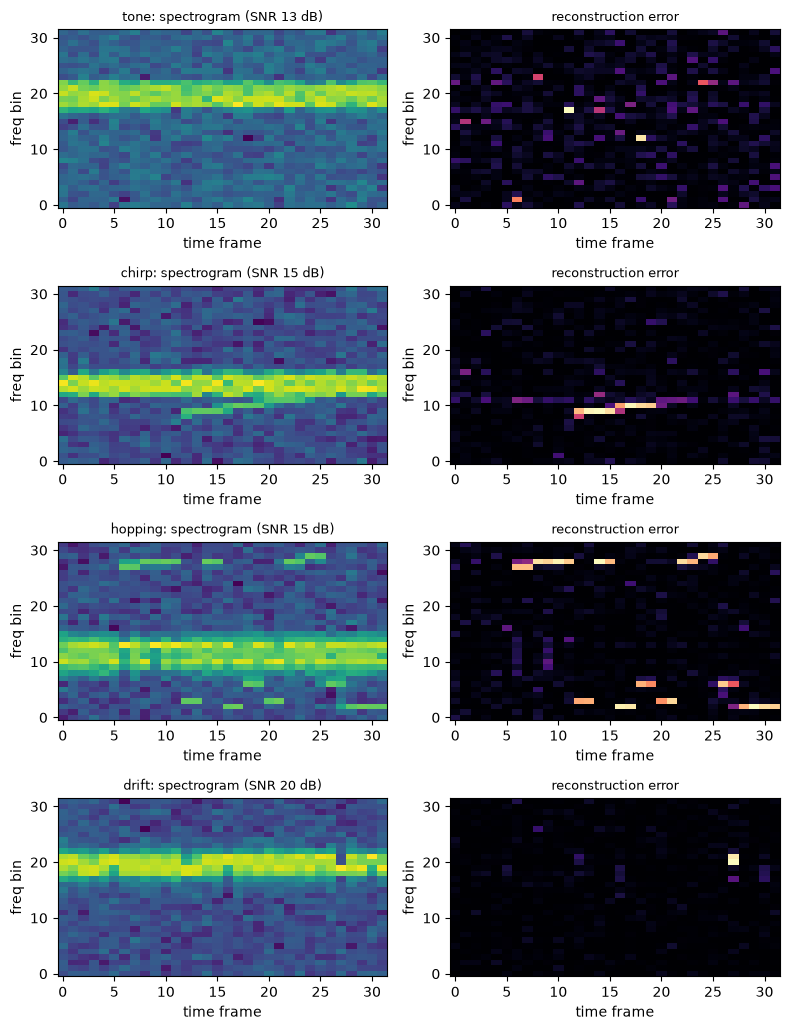

In [3]:
# CELL 10: CONVOLUTIONAL AUTOENCODER, BOTTLENECK EXPERIMENT AND HEATMAPS
# What this cell does:
#   - Trains the conv autoencoder on the normal TRAIN spectrograms with
#     bottleneck 4, 16 and 64.
#   - For each, sets thresholds on VALIDATION normals, applies them to TEST and
#     prints: test FAR, and per-family AUROC for the "mean" and "max" scores.
#   - For bottleneck 16 also prints the full family table (AUROC, AUPRC, det@1%,
#     det@5%) for the "mean" score.
#   - Saves figures/error_heatmaps.png: for tone, chirp, hopping and drift, the
#     first anomalous TEST window above 10 dB SNR, its spectrogram and its
#     error map (bottleneck 16, "mean" model).
#   - Takes roughly 3 to 8 minutes on CPU.

import time
import numpy as np
import matplotlib.pyplot as plt
from src.models.conv_ae import ConvAEDetector
from src.eval.metrics import auroc, family_report, false_alarm_rate, threshold_at_far

vn = va["y"] == 0
nrm, anm = te["y"] == 0, te["y"] == 1
fams = sorted(str(f) for f in set(te["family"][anm]))

def fam_auc(s, f):
    return auroc(s[nrm], s[anm & (te["family"] == f)])

models = {}
for b in (4, 16, 64):
    t0 = time.time()
    m = ConvAEDetector(bottleneck=b).fit(tr["spec"])
    models[b] = m
    print(f"\nbottleneck {b}: trained in {time.time() - t0:.0f}s, epochs run {m.epochs_run}")
    for mode in ("mean", "max"):
        sv, st = m.score(va["spec"], mode), m.score(te["spec"], mode)
        t5 = threshold_at_far(sv[vn], 0.05)
        print(f"  {mode:4s} | test FAR@5% {false_alarm_rate(st[nrm], t5):.3f} | AUROC " +
              " ".join(f"{f[:6]} {fam_auc(st, f):.3f}" for f in fams))

m = models[16]
sv, st = m.score(va["spec"]), m.score(te["spec"])
t1, t5 = threshold_at_far(sv[vn], 0.01), threshold_at_far(sv[vn], 0.05)
r1, r5 = family_report(st, te["y"], te["family"], t1), family_report(st, te["y"], te["family"], t5)
print("\nConv AE, bottleneck 16, mean score")
print(f"  {'family':12s} | {'n':>4s} | {'AUROC':>6s} | {'AUPRC':>6s} | {'det@1%':>6s} | {'det@5%':>6s}")
for fam, r in r1.items():
    print(f"  {fam:12s} | {r['n']:4d} | {r['auroc']:6.3f} | {r['auprc']:6.3f} | "
          f"{r['det_rate']:6.3f} | {r5[fam]['det_rate']:6.3f}")

show = []
for fam in ["tone", "chirp", "hopping", "drift"]:
    idx = np.where(anm & (te["family"] == fam) & (te["snr_db"] > 10))[0]
    if len(idx):
        show.append((fam, idx[0]))
emaps = m.error_map(te["spec"][[i for _, i in show]])
fig, axes = plt.subplots(len(show), 2, figsize=(8, 2.6 * len(show)))
for r, ((fam, i), em) in enumerate(zip(show, emaps)):
    axes[r, 0].imshow(te["spec"][i].reshape(32, 32).T, origin="lower", aspect="auto", cmap="viridis")
    axes[r, 0].set_title(f"{fam}: spectrogram (SNR {te['snr_db'][i]:.0f} dB)", fontsize=9)
    axes[r, 1].imshow(em.T, origin="lower", aspect="auto", cmap="magma")
    axes[r, 1].set_title("reconstruction error", fontsize=9)
    for a in axes[r]:
        a.set_xlabel("time frame"); a.set_ylabel("freq bin")
fig.tight_layout()
(project_root / "figures").mkdir(exist_ok=True)
fig.savefig(project_root / "figures" / "error_heatmaps.png", dpi=200)
plt.show()

In [4]:
# CELL 11: CONV AE, 60 vs 150 EPOCHS
# What this cell does:
#   - Trains the conv autoencoder (bottleneck 16) for up to 150 epochs (early
#     stopping with patience 10) and compares its TEST AUROC per family with the
#     60-epoch model from Cell 10.
#   - Needs Cells 7 and 10 (tr, va, te, models).

import time
import numpy as np
from src.models.conv_ae import ConvAEDetector
from src.eval.metrics import auroc

nrm, anm = te["y"] == 0, te["y"] == 1
fams = sorted(str(f) for f in set(te["family"][anm]))
def fam_auc(s, f):
    return auroc(s[nrm], s[anm & (te["family"] == f)])

t0 = time.time()
long = ConvAEDetector(bottleneck=16, epochs=150, patience=10).fit(tr["spec"])
print(f"trained in {time.time() - t0:.0f}s")
print(f"{'model':11s} {'epochs':>6s} | " + " ".join(f"{f[:8]:>8s}" for f in fams))
for name, m in [("60 epochs", models[16]), ("150 epochs", long)]:
    s = m.score(te["spec"])
    print(f"{name:11s} {m.epochs_run:6d} | " + " ".join(f"{fam_auc(s, f):8.3f}" for f in fams))

trained in 148s
model       epochs |    chirp    drift  hopping mod_swap noise_bu     tone
60 epochs       60 |    0.929    0.740    0.930    0.480    0.576    0.854
150 epochs     137 |    0.930    0.737    0.931    0.487    0.576    0.838


In [5]:
# CELL 12: FIVE SEEDS, MEAN ± STD
# What this cell does:
#   - For seeds 0..4 trains Isolation Forest, the scikit-learn autoencoder and
#     the conv autoencoder (bottleneck 16). One-Class SVM has no randomness, so
#     it is trained once.
#   - Builds two fused detectors ("mean" fusion): fusion3 = IF + OCSVM + sklearn
#     AE (as in Cell 8), fusion4 = fusion3 + conv AE.
#   - Thresholds come from VALIDATION normals (5% false alarms), applied to TEST.
#   - Prints mean ± std over seeds of: test AUROC per family, detection rate at
#     5% FAR per family, and test FAR. Saves figures/seeds_auroc.csv.
#   - Needs Cell 7 (tr, va, te).

import csv
import time
import numpy as np
from src.data.loading import load_features
from src.dsp.features import FEATURE_NAMES
from src.models.classical import isolation_forest, one_class_svm
from src.models.autoencoder import AutoencoderDetector
from src.models.conv_ae import ConvAEDetector
from src.models.fusion import ScoreFusion
from src.eval.metrics import auroc, detection_rate, false_alarm_rate, threshold_at_far
from src.eval.seeds import mean_std

CONV_EPOCHS = 60
SEEDS = [0, 1, 2, 3, 4]

F = {s: load_features(s, project_root / "data") for s in ["train", "val", "test"]}
assert np.array_equal(F["val"]["y"], va["y"]) and np.array_equal(F["test"]["y"], te["y"]), "row order mismatch"
no_snr = [n for n in FEATURE_NAMES if n not in ("power_db", "peak_to_median_db", "dynamic_range_db")]
vn = va["y"] == 0
nrm, anm = te["y"] == 0, te["y"] == 1
fams = sorted(str(f) for f in set(te["family"][anm]))

def fam_mask(f):
    return anm & (te["family"] == f)

svm = one_class_svm(nu=0.05, feature_names=no_snr).fit(F["train"]["feat"])
svm_val, svm_te = svm.score(F["val"]["feat"]), svm.score(F["test"]["feat"])

auc_runs, det_runs, far_runs = {}, {}, {}
for seed in SEEDS:
    t0 = time.time()
    d_if = isolation_forest(seed=seed).fit(F["train"]["feat"])
    d_ae = AutoencoderDetector(seed=seed).fit(tr["spec"])
    d_cv = ConvAEDetector(bottleneck=16, seed=seed, epochs=CONV_EPOCHS).fit(tr["spec"])
    sv = {"IF": d_if.score(F["val"]["feat"]), "OCSVM": svm_val,
          "AE": d_ae.score(va["spec"]), "ConvAE": d_cv.score(va["spec"])}
    st = {"IF": d_if.score(F["test"]["feat"]), "OCSVM": svm_te,
          "AE": d_ae.score(te["spec"]), "ConvAE": d_cv.score(te["spec"])}
    for name, keys in [("fusion3", ["IF", "OCSVM", "AE"]),
                       ("fusion4", ["IF", "OCSVM", "AE", "ConvAE"])]:
        fus = ScoreFusion("mean").fit([sv[k][vn] for k in keys])
        sv[name] = fus.combine([sv[k] for k in keys])
        st[name] = fus.combine([st[k] for k in keys])
    for name in st:
        t5 = threshold_at_far(sv[name][vn], 0.05)
        auc_runs.setdefault(name, []).append({f: auroc(st[name][nrm], st[name][fam_mask(f)]) for f in fams})
        det_runs.setdefault(name, []).append({f: detection_rate(st[name][fam_mask(f)], t5) for f in fams})
        far_runs.setdefault(name, []).append({"FAR": false_alarm_rate(st[name][nrm], t5)})
    print(f"seed {seed} done in {time.time() - t0:.0f}s")

def show(title, runs, fmt="{:.3f}±{:.3f}"):
    print(f"\n{title}")
    keys = list(next(iter(runs.values()))[0])
    print(f"{'detector':9s} " + " ".join(f"{k[:9]:>13s}" for k in keys))
    for name, r in runs.items():
        ms = mean_std(r)
        print(f"{name:9s} " + " ".join(f"{fmt.format(*ms[k]):>13s}" for k in keys))

show("TEST AUROC, mean ± std over 5 seeds", auc_runs)
show("DETECTION RATE at 5% FAR, mean ± std", det_runs)
show("TEST FAR at 5% target, mean ± std", far_runs)

(project_root / "figures").mkdir(exist_ok=True)
with open(project_root / "figures" / "seeds_auroc.csv", "w", newline="") as fh:
    wr = csv.writer(fh)
    wr.writerow(["detector"] + [f"{f}_mean,{f}_std" for f in fams])
    for name, r in auc_runs.items():
        ms = mean_std(r)
        wr.writerow([name] + [f"{ms[f][0]:.4f},{ms[f][1]:.4f}" for f in fams])

seed 0 done in 129s
seed 1 done in 108s
seed 2 done in 163s
seed 3 done in 146s
seed 4 done in 171s

TEST AUROC, mean ± std over 5 seeds
detector          chirp         drift       hopping      mod_swap     noise_bur          tone
IF          0.954±0.008   0.918±0.006   0.905±0.009   0.477±0.010   0.681±0.015   0.771±0.005
OCSVM       0.985±0.000   0.960±0.000   0.911±0.000   0.509±0.000   0.625±0.000   0.621±0.000
AE          0.877±0.002   0.631±0.002   0.951±0.001   0.515±0.004   0.609±0.004   0.813±0.004
ConvAE      0.929±0.002   0.742±0.002   0.929±0.002   0.477±0.002   0.575±0.003   0.850±0.005
fusion3     0.983±0.001   0.943±0.002   0.958±0.004   0.502±0.004   0.660±0.007   0.869±0.004
fusion4     0.981±0.001   0.932±0.002   0.960±0.004   0.492±0.003   0.648±0.006   0.887±0.002

DETECTION RATE at 5% FAR, mean ± std
detector          chirp         drift       hopping      mod_swap     noise_bur          tone
IF          0.747±0.040   0.672±0.030   0.646±0.023   0.087±0.006   0.201

In [6]:
# CELL 13: DISTRIBUTION SHIFT IN SNR
# What this cell does:
#   - Trains each detector twice: (A) on all normal TRAIN windows, (B) only on
#     normal TRAIN windows with SNR >= 10 dB.
#   - Threshold (5% false alarms) is set on VALIDATION normals from the same
#     SNR range the detector was trained on (A: all, B: SNR >= 10).
#   - Prints the TEST false-alarm rate per SNR bin, and the overall detection
#     rate on anomalous windows, for each detector and training condition.
#   - Needs Cell 7 (tr, va, te).

import numpy as np
from src.data.loading import load_features
from src.dsp.features import FEATURE_NAMES
from src.models.classical import isolation_forest, one_class_svm
from src.models.autoencoder import AutoencoderDetector
from src.eval.metrics import detection_rate, rate_by_bin, threshold_at_far

F = {s: load_features(s, project_root / "data") for s in ["train", "val", "test"]}
assert np.array_equal(F["val"]["y"], va["y"]) and np.array_equal(F["test"]["y"], te["y"])
no_snr = [n for n in FEATURE_NAMES if n not in ("power_db", "peak_to_median_db", "dynamic_range_db")]
edges = np.array([-5, 0, 5, 10, 15, 20, 25.1])
nrm, anm = te["y"] == 0, te["y"] == 1

makers = {
    "IF":    (lambda: isolation_forest(), "feat"),
    "OCSVM": (lambda: one_class_svm(nu=0.05, feature_names=no_snr), "feat"),
    "AE":    (lambda: AutoencoderDetector(), "spec"),
}
def data(kind, split):
    return F[split]["feat"] if kind == "feat" else {"train": tr, "val": va, "test": te}[split]["spec"]

for name, (make, kind) in makers.items():
    for cond, lo in [("trained on all SNR", -99), ("trained on SNR>=10", 10)]:
        tm = tr["snr_db"] >= lo
        vm = (va["y"] == 0) & (va["snr_db"] >= lo)
        det = make().fit(data(kind, "train")[tm])
        thr = threshold_at_far(det.score(data(kind, "val"))[vm], 0.05)
        s = det.score(data(kind, "test"))
        fb = rate_by_bin(s[nrm], te["snr_db"][nrm], thr, edges)
        print(f"\n{name} | {cond} | train windows {tm.sum()} | "
              f"overall detection {detection_rate(s[anm], thr):.3f}")
        print("  FAR by SNR bin: " + "  ".join(f"{lo_:.0f}..{min(hi_,25):.0f}: {r:.3f}" for lo_, hi_, r, _ in fb))


IF | trained on all SNR | train windows 4500 | overall detection 0.440
  FAR by SNR bin: -5..0: 0.178  0..5: 0.022  5..10: 0.008  10..15: 0.002  15..20: 0.009  20..25: 0.068

IF | trained on SNR>=10 | train windows 2265 | overall detection 0.764
  FAR by SNR bin: -5..0: 1.000  0..5: 1.000  5..10: 0.907  10..15: 0.012  15..20: 0.000  20..25: 0.000

OCSVM | trained on all SNR | train windows 4500 | overall detection 0.517
  FAR by SNR bin: -5..0: 0.047  0..5: 0.020  5..10: 0.015  10..15: 0.017  15..20: 0.043  20..25: 0.054

OCSVM | trained on SNR>=10 | train windows 2265 | overall detection 0.863
  FAR by SNR bin: -5..0: 1.000  0..5: 1.000  5..10: 0.867  10..15: 0.006  15..20: 0.007  20..25: 0.008

AE | trained on all SNR | train windows 4500 | overall detection 0.401
  FAR by SNR bin: -5..0: 0.002  0..5: 0.012  5..10: 0.004  10..15: 0.027  15..20: 0.047  20..25: 0.125

AE | trained on SNR>=10 | train windows 2265 | overall detection 0.388
  FAR by SNR bin: -5..0: 0.102  0..5: 0.102  5.

In [7]:
import numpy as np
with np.load(project_root / "data" / "test.npz") as z:
    print(z.files)
    r = z["rec_id"]
    print("first 40 rec_id:", r[:40])
    print("windows per recording:", np.unique(r, return_counts=True)[1][:10])
    print("y of first anomalous recording:", z["y"][np.where(z["family"] != "normal")[0][:15]])

['x', 'y', 'family', 'snr_db', 'rec_id']
first 40 rec_id: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2
 2 2 2]
windows per recording: [15 15 15 15 15 15 15 15 15 15]
y of first anomalous recording: [ 0  0  0  0 -1  1  1  1  1  1  1 -1  0  0  0]


In [8]:
# CELL 14: DETECTION LATENCY
# What this cell does:
#   - Trains Isolation Forest, One-Class SVM and the spectrogram autoencoder
#     (seed 0) and fuses them ("mean"), as in Cell 8.
#   - Thresholds are set on VALIDATION normals at 1% and 5% false alarms.
#   - For every TEST recording with an anomaly, finds the first anomalous window
#     (label 1) and the last one, and looks for the first flagged window in that
#     span. Latency = windows between the start and that flag (0 = flagged at
#     once). One window step = 2048 samples.
#   - Prints per family: recordings, fraction detected at all, median and mean
#     latency (windows) among detected ones.
#   - Also prints the fraction of NORMAL recordings with at least one false
#     alarm among their windows.
#   - Needs Cell 7 (tr, va, te).

import numpy as np
from src.data.loading import load_features
from src.dsp.features import FEATURE_NAMES
from src.models.classical import isolation_forest, one_class_svm
from src.models.autoencoder import AutoencoderDetector
from src.models.fusion import ScoreFusion
from src.eval.metrics import threshold_at_far

F = {s: load_features(s, project_root / "data") for s in ["train", "val", "test"]}
assert np.array_equal(F["val"]["y"], va["y"]) and np.array_equal(F["test"]["y"], te["y"])

with np.load(project_root / "data" / "test.npz") as z:
    y_raw, rid_raw = z["y"], z["rec_id"]
assert np.all(np.unique(rid_raw, return_counts=True)[1] == 15), "not 15 windows per recording"
pos = (np.arange(len(y_raw)) % 15)[y_raw != -1]
rid = F["test"]["rec_id"]
assert len(pos) == len(rid) and np.array_equal(rid, rid_raw[y_raw != -1])

no_snr = [n for n in FEATURE_NAMES if n not in ("power_db", "peak_to_median_db", "dynamic_range_db")]
d_if = isolation_forest().fit(F["train"]["feat"])
d_sv = one_class_svm(nu=0.05, feature_names=no_snr).fit(F["train"]["feat"])
d_ae = AutoencoderDetector().fit(tr["spec"])
sv = [d_if.score(F["val"]["feat"]), d_sv.score(F["val"]["feat"]), d_ae.score(va["spec"])]
st = [d_if.score(F["test"]["feat"]), d_sv.score(F["test"]["feat"]), d_ae.score(te["spec"])]
vn = va["y"] == 0
fus = ScoreFusion("mean").fit([s[vn] for s in sv])
s_val, s_te = fus.combine(sv), fus.combine(st)

y, fam = te["y"], te["family"]
for far in (0.05, 0.01):
    thr = threshold_at_far(s_val[vn], far)
    flag = s_te > thr
    lat = {}
    normal_alarm = []
    for r in np.unique(rid):
        idx = np.where(rid == r)[0]
        idx = idx[np.argsort(pos[idx])]
        a = idx[y[idx] == 1]
        if len(a) == 0:
            if np.all(y[idx] == 0):
                normal_alarm.append(bool(flag[idx].any()))
            continue
        span = idx[(pos[idx] >= pos[a].min()) & (pos[idx] <= pos[a].max())]
        hits = span[flag[span]]
        lat.setdefault(str(fam[a[0]]), []).append(pos[hits[0]] - pos[a.min()] if len(hits) else None)
    print(f"\nFusion3 at {far:.0%} FAR | normal recordings with >=1 false alarm: "
          f"{np.mean(normal_alarm):.3f} (n={len(normal_alarm)})")
    print(f"  {'family':12s} | {'recs':>4s} | {'detected':>8s} | {'median lat':>10s} | {'mean lat':>8s}")
    for f in sorted(lat):
        d = [v for v in lat[f] if v is not None]
        print(f"  {f:12s} | {len(lat[f]):4d} | {len(d) / len(lat[f]):8.3f} | "
              f"{(np.median(d) if d else float('nan')):10.1f} | {(np.mean(d) if d else float('nan')):8.2f}")


Fusion3 at 5% FAR | normal recordings with >=1 false alarm: 0.240 (n=50)
  family       | recs | detected | median lat | mean lat
  chirp        |   50 |    1.000 |        0.0 |     0.10
  drift        |   50 |    0.980 |        0.0 |     0.65
  hopping      |   50 |    0.920 |        0.0 |     0.22
  mod_swap     |   50 |    0.180 |        0.0 |     1.33
  noise_burst  |   50 |    0.760 |        0.0 |     1.03
  tone         |   50 |    0.860 |        0.0 |     0.51

Fusion3 at 1% FAR | normal recordings with >=1 false alarm: 0.000 (n=50)
  family       | recs | detected | median lat | mean lat
  chirp        |   50 |    0.940 |        0.0 |     0.04
  drift        |   50 |    0.840 |        0.0 |     1.12
  hopping      |   50 |    0.860 |        0.0 |     0.14
  mod_swap     |   50 |    0.060 |        0.0 |     1.33
  noise_burst  |   50 |    0.600 |        0.0 |     0.77
  tone         |   50 |    0.700 |        0.0 |     0.57


In [9]:
# CELL 15: SPECTROGRAM ABLATIONS (NORMALISATION AND FRAME SIZE)
# What this cell does:
#   - Loads the raw I/Q windows (ambiguous removed) and builds spectrograms with
#     4 settings, always 32 frequency bins:
#       baseline        : frame 128, 32 frames, normalised
#       no normalisation: frame 128, 32 frames, level kept
#       frame 64        : 64 frames, normalised
#       frame 256       : 16 frames, normalised
#   - For each setting and seeds 0, 1, 2: trains the spectrogram autoencoder on
#     normal TRAIN windows, sets the 5% threshold on VALIDATION normals, and
#     applies it to TEST.
#   - Prints mean ± std over seeds of: test AUROC per family, and test false-alarm
#     rate overall and in the lowest (-5..0 dB) and highest (20..25 dB) SNR bins.
#   - Needs Cell 0.

import time
import numpy as np
from src.dsp.spectro import window_spectrogram
from src.models.autoencoder import AutoencoderDetector
from src.eval.metrics import auroc, false_alarm_rate, rate_by_bin, threshold_at_far
from src.eval.seeds import mean_std

raw = {}
for s in ["train", "val", "test"]:
    with np.load(project_root / "data" / f"{s}.npz") as z:
        keep = z["y"] != -1
        raw[s] = {"x": z["x"][keep], "y": z["y"][keep], "family": z["family"][keep],
                  "snr_db": z["snr_db"][keep]}

configs = {
    "baseline":         dict(n_frames=32, frame=128, pool=4, normalise=True),
    "no normalisation": dict(n_frames=32, frame=128, pool=4, normalise=False),
    "frame 64":         dict(n_frames=64, frame=64, pool=2, normalise=True),
    "frame 256":        dict(n_frames=16, frame=256, pool=8, normalise=True),
}
y_val, y_te = raw["val"]["y"], raw["test"]["y"]
vn, nrm, anm = y_val == 0, y_te == 0, y_te == 1
fams = sorted(str(f) for f in set(raw["test"]["family"][anm]))
snr_n = raw["test"]["snr_db"][nrm]
edges = np.array([-5, 0, 5, 10, 15, 20, 25.1])

auc_runs, far_runs = {}, {}
for name, cfg in configs.items():
    t0 = time.time()
    spec = {s: window_spectrogram(raw[s]["x"], **cfg) for s in raw}
    for seed in (0, 1, 2):
        det = AutoencoderDetector(seed=seed).fit(spec["train"])
        thr = threshold_at_far(det.score(spec["val"])[vn], 0.05)
        s_te = det.score(spec["test"])
        auc_runs.setdefault(name, []).append(
            {f: auroc(s_te[nrm], s_te[anm & (raw["test"]["family"] == f)]) for f in fams})
        fb = rate_by_bin(s_te[nrm], snr_n, thr, edges)
        far_runs.setdefault(name, []).append(
            {"FAR all": false_alarm_rate(s_te[nrm], thr),
             "FAR -5..0": fb[0][2], "FAR 20..25": fb[-1][2]})
    print(f"{name} done in {time.time() - t0:.0f}s ({spec['train'].shape[1]} inputs)")

def show(title, runs):
    print(f"\n{title}")
    keys = list(next(iter(runs.values()))[0])
    print(f"{'setting':17s} " + " ".join(f"{k[:10]:>13s}" for k in keys))
    for name, r in runs.items():
        ms = mean_std(r)
        print(f"{name:17s} " + " ".join(f"{ms[k][0]:.3f}±{ms[k][1]:.3f}".rjust(13) for k in keys))

show("TEST AUROC, mean ± std over 3 seeds", auc_runs)
show("TEST FALSE-ALARM RATE at 5% target, mean ± std", far_runs)

baseline done in 167s (1024 inputs)
no normalisation done in 283s (1024 inputs)
frame 64 done in 240s (2048 inputs)
frame 256 done in 134s (512 inputs)

TEST AUROC, mean ± std over 3 seeds
setting                   chirp         drift       hopping      mod_swap    noise_burs          tone
baseline            0.878±0.002   0.631±0.003   0.951±0.002   0.514±0.002   0.611±0.003   0.812±0.003
no normalisation    0.905±0.002   0.708±0.005   0.907±0.004   0.472±0.009   0.587±0.012   0.835±0.010
frame 64            0.853±0.002   0.635±0.004   0.904±0.001   0.456±0.001   0.565±0.007   0.806±0.002
frame 256           0.885±0.002   0.634±0.005   0.956±0.002   0.505±0.003   0.604±0.005   0.847±0.003

TEST FALSE-ALARM RATE at 5% target, mean ± std
setting                 FAR all     FAR -5..0    FAR 20..25
baseline            0.034±0.004   0.001±0.001   0.128±0.010
no normalisation    0.037±0.002   0.000±0.000   0.172±0.011
frame 64            0.031±0.002   0.000±0.000   0.148±0.011
frame 256    